# 3.1 Code Practice

## Script 1: Load, Clean, and Visualize the Iris Dataset

### Question

1. Load the Iris dataset into a pandas DataFrame.
2. Drop all rows where sepal length is greater than 5 cm.
3. Create a scatter plot of petal length versus sepal length, with each point color-coded by Iris species.
4. Explain what the measurements represent, their units, and what the filtering step accomplishes.

### My Approach and Justification

The Iris dataset contains measurements from 150 flowers belonging to three species: Setosa, Versicolor, and Virginica. Each flower has four numerical features: sepal length, sepal width, petal length, and petal width, measured in centimeters.

I first load the dataset into a pandas DataFrame because each row can represent one flower and each column can represent one feature. I then convert the numerical target values into species names to make the results easier to interpret.

Next, I keep only flowers with a sepal length of 5 cm or less. Finally, I plot sepal length against petal length and use different colors for the three species. This lets me visually examine whether these features help separate the flower species.

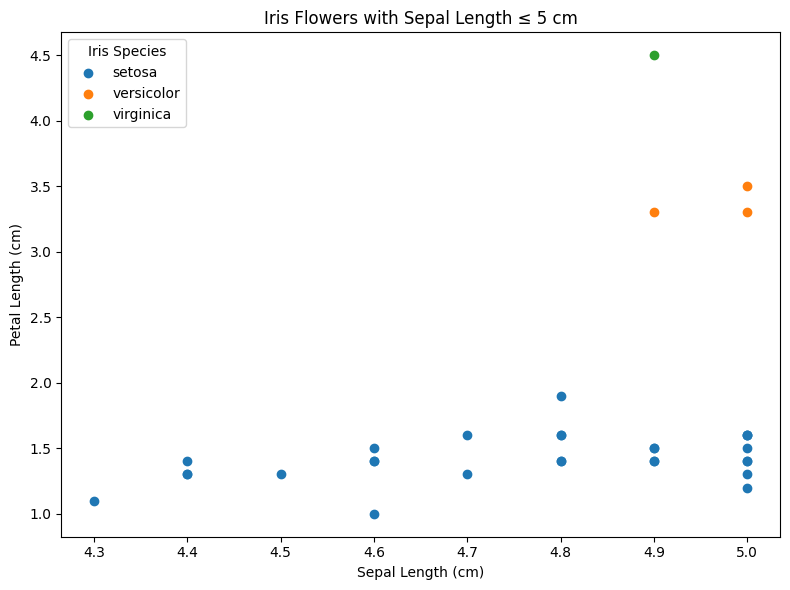

In [1]:
# Importing the libraries needed for storing, filtering, and visualizing the Iris dataset.
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris

# STEP 1: Loading the Iris dataset.
# The Iris dataset contains measurements from 150 iris flowers.
# There are three species: Setosa, Versicolor, and Virginica.
# Each flower has four measurements:
# sepal length, sepal width, petal length, and petal width.
# All measurements are recorded in centimeters (cm).

iris = load_iris(as_frame=True)

# Copying the dataset into a pandas DataFrame.
# Each row represents one flower.
# Each measurement column represents one feature of that flower.
df = iris.frame.copy()

# Converting the numerical target values into actual species names.
# 0 = Setosa, 1 = Versicolor, 2 = Virginica.
# Adding species names makes the final visualization easier to interpret.
df["species"] = df["target"].map({
    0: iris.target_names[0],
    1: iris.target_names[1],
    2: iris.target_names[2]
})

# STEP 2: Filtering the dataset.
# Keeping only flowers with a sepal length of 5 cm or less.
# Each removed row therefore represents a flower whose sepal is longer than 5 cm.
df_filtered = df[df["sepal length (cm)"] <= 5].copy()

# STEP 3: Creating the scatter plot.
# Each point represents one flower.
# The x-axis represents sepal length.
# The y-axis represents petal length.
# Plotting each species separately gives each species a different color.
plt.figure(figsize=(8, 6))

for species in df_filtered["species"].unique():

    # Selecting flowers belonging to the current species.
    species_data = df_filtered[df_filtered["species"] == species]

    # Plotting the selected flowers.
    plt.scatter(
        species_data["sepal length (cm)"],
        species_data["petal length (cm)"],
        label=species
    )

# STEP 4: Adding labels so the graph can be interpreted without reading the code.
plt.title("Iris Flowers with Sepal Length ≤ 5 cm")
plt.xlabel("Sepal Length (cm)")
plt.ylabel("Petal Length (cm)")

# Showing which color represents each Iris species.
plt.legend(title="Iris Species", loc="upper left")

# Adjusting the layout so labels are not cut off.
plt.tight_layout()

# Displaying the completed scatter plot.
plt.show()

### Interpretation

The scatter plot shows the relationship between **sepal length** and **petal length** for flowers with sepal lengths of 5 cm or less. Each point represents one flower, and its color identifies its species.

The plot shows that different species can occupy different parts of the feature space. This demonstrates the purpose of **exploratory data analysis**: visualizing features before training a model can help reveal useful patterns in the data.

In machine learning terms:

- **Observation:** one flower
- **Features:** sepal and petal measurements
- **Label:** Iris species
- **Preprocessing:** filtering flowers by sepal length
- **Visualization:** examining the relationship between two features

# Script 2: Load, Clean, and Visualize the MNIST Handwritten Digits Dataset

### Question

1. Load the MNIST dataset into a pandas DataFrame.
2. Drop all digits except 3 and 8.
3. Visualize an array of MNIST digits to observe variation in handwriting.
4. Explain what the images represent, how they are stored, and what the plotting function does.

### My Approach and Justification

MNIST contains grayscale images of handwritten digits from 0 to 9. Each image is 28 × 28 pixels, meaning that one image contains:

**28 × 28 = 784 pixel values**

For the computer, an image can therefore be represented numerically using 784 features. I store each image as one row of a DataFrame, where the 784 pixel positions are the feature columns and an additional `label` column contains the correct digit.

I then filter the dataset so that only examples of **3** and **8** remain. I randomly select examples of each digit to show variation in how different people write the same number.

To display an image, I reshape its 784-value row back into a 28 × 28 grid. The plotting function then converts the numerical pixel intensities into visible grayscale pixels.

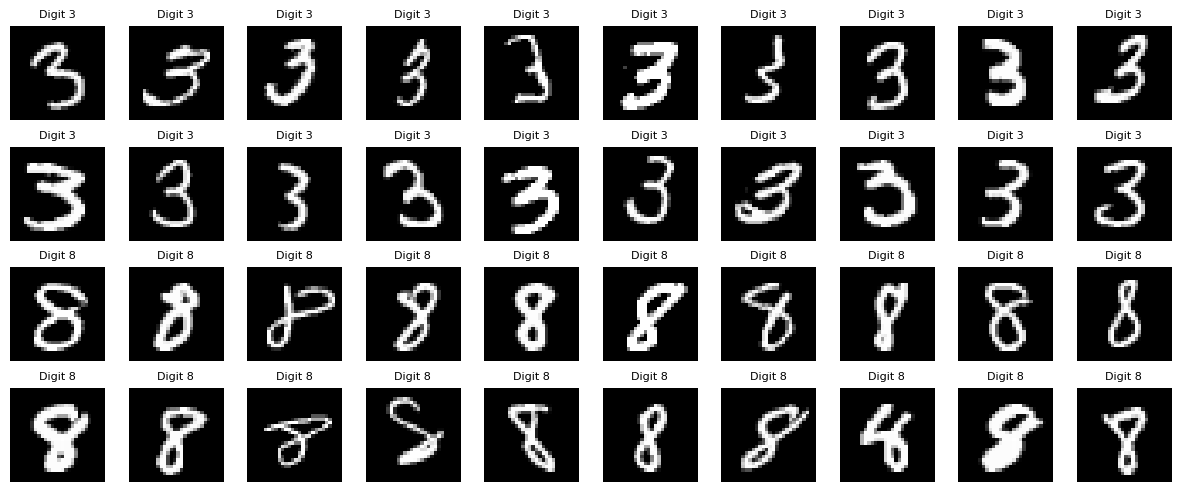

In [2]:
# Importing the libraries needed for storing, filtering, and visualizing MNIST.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

# STEP 1: Loading the MNIST handwritten digit dataset.
# MNIST contains handwritten digits from 0 through 9.
# Each image is 28 pixels wide and 28 pixels tall.
# Therefore, each image contains 28 x 28 = 784 pixels.
mnist = fetch_openml(
    name="mnist_784",
    version=1,
    as_frame=False)

# Separating the image features from their correct labels.
# X contains the pixel values.
# y contains the correct digit represented by each image.
X = mnist.data
y = mnist.target.astype(int)

# Creating names for the 784 pixel columns.
pixel_cols = [f"pixel{i}" for i in range(X.shape[1])]

# Converting the image data into a pandas DataFrame.
# Each row represents one handwritten image.
# Each column represents one of its 784 pixel positions.
df = pd.DataFrame(X, columns=pixel_cols)

# Adding the correct digit label to each image.
# The label applies to the complete image, not to individual pixels.
df["label"] = y

# STEP 2: Filtering the dataset.
# Keeping only images whose correct labels are 3 or 8.
# All other handwritten digits are removed.
df_38 = df[df["label"].isin([3, 8])].copy()

# STEP 3: Selecting examples to visualize.
# Selecting 20 examples of digit 3 and 20 examples of digit 8.
# random_state=42 makes the selection reproducible.
n_per_digit = 20

samples_3 = df_38[df_38["label"] == 3].sample(
    n=n_per_digit,
    random_state=42)

samples_8 = df_38[df_38["label"] == 8].sample(
    n=n_per_digit,
    random_state=42)

# Combining the selected examples into one DataFrame.
grid_df = pd.concat([samples_3, samples_8])

# STEP 4: Creating a grid containing 40 plotting areas.
# Each plotting area will display one handwritten digit.
fig, axes = plt.subplots(
    nrows=4,
    ncols=10,
    figsize=(12, 5))

# Flattening the plotting grid so each image can be processed one at a time.
axes = axes.ravel()

# Displaying each selected handwritten digit.
for ax, (_, row) in zip(axes, grid_df.iterrows()):

    # Extracting the 784 numerical pixel values for one image.
    pixel_values = row[pixel_cols].to_numpy(dtype=np.uint8)

    # Reshaping the 784-value vector back into its original 28 x 28 image layout.
    image = pixel_values.reshape(28, 28)

    # Converting the numerical pixel intensities into a visible grayscale image.
    ax.imshow(
        image,
        cmap="gray",
        interpolation="nearest"
    )

    # Showing the correct digit above each image.
    ax.set_title(
        f"Digit {int(row['label'])}",
        fontsize=8
    )

    # Removing coordinate axes because the goal is to inspect the handwriting.
    ax.axis("off")

# Adjusting spacing so the images and labels do not overlap.
plt.tight_layout()

# Displaying the completed image grid.
plt.show()

### Interpretation

The visualization shows multiple handwritten examples of **3s and 8s**. Although images within each group have the same label, their exact shapes and pixel patterns differ because different people write the same digit differently.

The computer does not initially understand an image as a "3" or an "8." Instead, each image is represented by **784 numerical pixel features**, while the `label` column tells us which digit the complete image represents.

This gives the supervised-learning structure:


x = 784 pixel values



y = digit label

This exercise also shows why preprocessing matters. The image is stored as a one-dimensional sequence of 784 values in the DataFrame, but it must be reshaped into a **28 × 28 matrix** before it can be displayed as the image humans recognize.

### Connection to the Machine Learning Pipeline

These two exercises mainly cover the beginning of the machine learning pipeline:

**Data → Preprocessing → Visualization**

For Iris, the inputs are numerical flower measurements. For MNIST, the inputs are numerical pixel intensities. Although the raw data look very different to humans, both can be represented as numerical features that a machine learning model could later use for prediction.

No predictive model is trained in these exercises. The purpose is to understand the observations, features, labels, filtering, and representation of the data before applying a machine learning algorithm.